In [2]:
import pandas as pd
import numpy as np

In [3]:
#reading the raw csv
df = pd.read_csv(r"C:\Users\Harsh\Documents\criteo_uplift\data\raw\criteo-uplift-v2.1.csv\criteo-uplift-v2.1.csv")   # compression inferred from extension


In [4]:
## reading the read_me

with open(r"C:\Users\Harsh\Documents\criteo_uplift\criteo_uplift_project_README.md", "r", encoding="utf-8") as f:
    content = f.read()

print(content)


# Incremental Marketing & Customer Response Modeling

## Project Overview

This project focuses on **incremental marketing measurement and uplift modeling**.

The central question is not simply:

> **Which customers are most likely to buy?**

Instead, we want to answer the more important marketing question:

> **Which customers are more likely to buy because we showed them an advertisement?**

This distinction is the foundation of the project.

A customer may have a very high probability of purchasing even if we do nothing. Spending advertising money on that customer may therefore generate little or no incremental value.

Another customer may have a low baseline probability of purchasing, but advertising could substantially increase their probability of conversion. That customer may be much more valuable to target.

The project will therefore move from conventional predictive modeling toward **causal inference, heterogeneous treatment effects, and uplift modeling**.

---

## The Busine

In [ ]:
# Fields

# Here is a detailed description of the fields (they are comma-separated in the file):

#     f0, f1, f2, f3, f4, f5, f6, f7, f8, f9, f10, f11: feature values (dense, float)
#     treatment: treatment group (1 = treated, 0 = control)
#     conversion: whether a conversion occured for this user (binary, label)
#     visit: whether a visit occured for this user (binary, label)
#     exposure: treatment effect, whether the user has been effectively exposed (binary)

# Key figures

#     Format: CSV
#     Size: 459MB (compressed)
#     Rows: 25,309,483
#     Average Visit Rate: .04132
#     Average Conversion Rate: .00229
#     Treatment Ratio: .846


In [5]:
df.head(10),df.shape

(          f0         f1        f2        f3         f4        f5        f6  \
 0  12.616365  10.059654  8.976429  4.679882  10.280525  4.115453  0.294443   
 1  12.616365  10.059654  9.002689  4.679882  10.280525  4.115453  0.294443   
 2  12.616365  10.059654  8.964775  4.679882  10.280525  4.115453  0.294443   
 3  12.616365  10.059654  9.002801  4.679882  10.280525  4.115453  0.294443   
 4  12.616365  10.059654  9.037999  4.679882  10.280525  4.115453  0.294443   
 5  12.616365  10.059654  8.904507  4.679882  10.280525  4.115453  0.294443   
 6  12.616365  10.059654  8.783340  4.679882  10.280525  4.115453  0.294443   
 7  12.616365  10.059654  8.964528  4.679882  10.280525  4.115453  0.294443   
 8  12.616365  10.059654  9.037809  4.679882  10.280525  4.115453  0.294443   
 9  12.616365  10.059654  9.015128  4.679882  10.280525  4.115453  0.294443   
 
          f7        f8         f9       f10       f11  treatment  conversion  \
 0  4.833815  3.955396  13.190056  5.300375 -0.16

In [6]:
df.dtypes

f0            float64
f1            float64
f2            float64
f3            float64
f4            float64
f5            float64
f6            float64
f7            float64
f8            float64
f9            float64
f10           float64
f11           float64
treatment       int64
conversion      int64
visit           int64
exposure        int64
dtype: object

In [7]:
df.describe()

,f0,f1,f2,f3,f4,f5,f6,f7,f8,f9,f10,f11,treatment,conversion,visit,exposure
count,1.397959e+07,1.397959e+07,1.397959e+07,1.397959e+07,1.397959e+07,1.397959e+07,1.397959e+07,1.397959e+07,1.397959e+07,1.397959e+07,1.397959e+07,1.397959e+07,1.397959e+07,1.397959e+07,1.397959e+07,1.397959e+07
mean,1.962030e+01,1.006998e+01,8.446582e+00,4.178923e+00,1.033884e+01,4.028513e+00,-4.155356e+00,5.101765e+00,3.933581e+00,1.602764e+01,5.333396e+00,-1.709672e-01,8.500001e-01,2.916680e-03,4.699200e-02,3.063122e-02
std,5.377464e+00,1.047557e-01,2.993161e-01,1.336645e+00,3.433081e-01,4.310974e-01,4.577914e+00,1.205248e+00,5.665958e-02,7.018975e+00,1.682288e-01,2.283277e-02,3.570713e-01,5.392748e-02,2.116217e-01,1.723164e-01
min,1.261636e+01,1.005965e+01,8.214383e+00,-8.398387e+00,1.028053e+01,-9.011892e+00,-3.142978e+01,4.833815e+00,3.635107e+00,1.319006e+01,5.300375e+00,-1.383941e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,1.261636e+01,1.005965e+01,8.214383e+00,4.679882e+00,1.028053e+01,4.115453e+00,-6.699321e+00,4.833815e+00,3.910792e+00,1.319006e+01,5.300375e+00,-1.686792e-01,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
50%,2.192341e+01,1.005965e+01,8.214383e+00,4.679882e+00,1.028053e+01,4.115453e+00,-2.411115e+00,4.833815e+00,3.971858e+00,1.319006e+01,5.300375e+00,-1.686792e-01,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
75%,2.443646e+01,1.005965e+01,8.723335e+00,4.679882e+00,1.028053e+01,4.115453e+00,2.944427e-01,4.833815e+00,3.971858e+00,1.319006e+01,5.300375e+00,-1.686792e-01,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
max,2.674526e+01,1.634419e+01,9.051962e+00,4.679882e+00,2.112351e+01,4.115453e+00,2.944427e-01,1.199840e+01,3.971858e+00,7.529502e+01,6.473917e+00,-1.686792e-01,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00


### Why missing values matter more here than in normal ML

In a regular predictive model, missing values are mostly a nuisance: drop or impute,
and you lose some accuracy.

In uplift/causal work there's an extra failure mode: missingness can **silently
unbalance the treatment vs. control groups** that randomization was supposed to
make comparable.

- **Dropping rows**: if rows with missing values aren't missing at random — e.g.
  disproportionately from one group, or from a particular type of customer — dropping
  them changes the composition of treatment vs. control. The experiment quietly stops
  being as random as it was, and any ATE/uplift estimate downstream inherits that bias,
  with no error message to warn you.
- **Imputing values**: if imputation is done carelessly (e.g. a column mean computed
  across both groups together) it can smuggle information between treatment and
  control, or distort a feature's relationship with the outcome in a way that
  specifically affects the treatment-effect estimate, not just general model accuracy.

The habit this builds: in normal ML you ask *"did dropping/imputing hurt accuracy?"*.
In causal/uplift work you additionally ask *"did dropping/imputing change the balance
between treatment and control?"*

This dataset is expected to be clean, so we don't expect to find anything here — the
point of checking is to rule this out, not because we expect a problem.

In [8]:
## checking for missing values 
## reason being its a good practice to know about the quality of data, 
## but also because UPLIFT/CAUSAL WORK IS SENSITIVE TO SILENTLY DROPPED OR IMPUTED ROWS

df.isna().sum()

f0            0
f1            0
f2            0
f3            0
f4            0
f5            0
f6            0
f7            0
f8            0
f9            0
f10           0
f11           0
treatment     0
conversion    0
visit         0
exposure      0
dtype: int64

In [13]:
df.info(memory_usage='deep')

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13979592 entries, 0 to 13979591
Data columns (total 16 columns):
 #   Column      Dtype  
---  ------      -----  
 0   f0          float64
 1   f1          float64
 2   f2          float64
 3   f3          float64
 4   f4          float64
 5   f5          float64
 6   f6          float64
 7   f7          float64
 8   f8          float64
 9   f9          float64
 10  f10         float64
 11  f11         float64
 12  treatment   int64  
 13  conversion  int64  
 14  visit       int64  
 15  exposure    int64  
dtypes: float64(12), int64(4)
memory usage: 1.7 GB


In [10]:
df.duplicated().sum()

np.int64(1259545)

In [19]:
df_dedup = df.drop_duplicates()
df_dedup['treatment'].mean()


np.float64(0.839003110601714)

In [ ]:
## checking if treatment =1 (treated groups) are being disproportionately affected by the removal of duplicate rows
df[df.duplicated()]['treatment'].mean()


np.float64(0.9610581598910718)

In [15]:
df['treatment'].mean()
 # sum of all values / count of all values = (number of 1s) / total rows
#df['treatment'].value_counts(normalize=True) # for each unique value, (count of that value) / total rows

np.float64(0.8500001287591226)

### Finding: duplicates are skewed toward the treated group, and there's no customer ID to resolve it cleanly

- `df.duplicated().sum()` → 1,259,545 exact-duplicate rows (~9% of 13,979,592).
- Treatment mean on full data: **0.850**. Treatment mean after `drop_duplicates()`: **0.839**.
  Treatment mean *within the duplicate rows only*: **0.961** — duplicates are heavily
  concentrated in the treated group, far more than the overall 85% treatment ratio.
- This dataset has **no customer ID column**. Checked Criteo's own documentation: the
  official page/paper describe this dataset as "one row per user," but independent
  analysis of the actual data shows only ~9.17M distinct covariate combinations
  (ignoring `f2`) exist across 13.98M rows — `f2` is the only feature that varies
  within an otherwise-identical group, so the other 11 features behave like a
  "proxy user ID." That reconstruction is known to be imperfect: ~3.4% of these
  proxy-ID groups contain rows from *both* treatment arms, which a real single
  customer cannot do. So some apparent "repeated customer" rows are actually
  coincidental collisions between different customers sharing a feature bucket.

**Why this matters:** blindly dropping duplicates would disproportionately remove
real treated-group rows, risking the same group-imbalance problem as carelessly
dropping missing values. But keeping them risks reweighting/clustering issues if
they really are repeated impressions from the same customer (see "Unit of
Randomization vs. Unit of Analysis" in `reports/concepts_and_resources.md`).

**Decision for now:** don't resolve this at the understanding stage. Proceed with
the full dataset. When computing the first real ATE (Session 6 — treatment vs.
control conversion rate), run it both with and without duplicates removed as a
robustness check, and document whichever outcome occurs as a stated limitation
in the final write-up. Full reasoning and sources logged in
`reports/concepts_and_resources.md`.

In [ ]:
## Session 3 — group distributions, explicitly via value_counts(normalize=True)
## (treatment already checked above; visit/conversion/exposure here)
print(df['visit'].value_counts(normalize=True))
print(df['conversion'].value_counts(normalize=True))
print(df['exposure'].value_counts(normalize=True))

### Session 3 write-up: comparing actual rates to documented figures

| Metric | Documented | Actual (this dataset) |
|---|---|---|
| Treatment ratio | .846 | .850 |
| Visit rate | .04132 | .04699 |
| Conversion rate | .00229 | .00292 |
| Exposure rate | *(not documented)* | .03063 |

All four actual rates are close to the documented figures but not exact —
treatment ratio is off by 0.4pp, visit rate by ~13.7% relative, conversion
rate by ~27% relative. This isn't a red flag: the documented figures almost
certainly describe the **original 25.3M-row release** (the same source as
the stale `# Rows: 25,309,483` comment earlier in this notebook), while this
project's actual data is the **13,979,592-row "unbiased" v2.1 subsample**,
which Criteo deliberately re-sampled to remove confounding present in the
original release. A deliberate re-sampling step changing these rates somewhat
is expected, not a sign of a loading error — especially since dtypes, nulls,
and shape all checked out clean earlier.

**Phase 1 (Understand the Dataset and Business Problem) is now complete.**
Moving to Phase 2, Session 4.

## Phase 2, Session 4 — Feature distributions

**Task:** look at the distribution of each of `f0`–`f11` — histograms and/or
summary stats (`describe()` per feature, or plotted).

**Concept:** you've already seen the numeric summary (`df.describe()` above)
— this session is about actually *looking* at shape, not just reading mean/std
numbers. Specifically worth noticing:

- **Skew and outliers** — several features already showed suspicious patterns
  in `describe()` (e.g. `f6` ranges from -31.4 to 0.29, `f9` has a max of 75.3
  against a 25th percentile of 13.19 — that's a long right tail). Plotting
  will show you *how* skewed, not just that min/max look wide.
- **Low cardinality / bucketing** — you already know from the duplicates
  investigation that several features repeat heavily (e.g. `f1`, `f4`, `f7`,
  `f8`, `f10` showed identical values across many rows in `head(10)`). A
  histogram will show you whether a feature is close to continuous or
  effectively a small set of discrete buckets — directly relevant later when
  deciding how to handle these features in a model.
- **Why this matters for *this* project specifically:** distribution shape
  affects how you'll scale/transform features for Phase 3's baseline models,
  and bucketed/discrete-looking features are a stronger hint toward the
  "proxy ID" hypothesis from the duplicates investigation — if you see a
  feature with only a handful of distinct values, that's consistent with it
  being a hashed/bucketed categorical rather than a true continuous
  measurement.

Write the code yourself — a loop over `f0`–`f11` with `.hist()` or
`df[col].describe()` per column is a reasonable starting point. Share what
you find, especially anything that looks surprisingly skewed or low-cardinality.

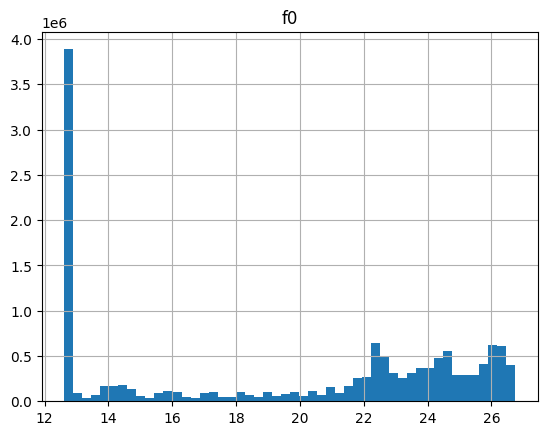

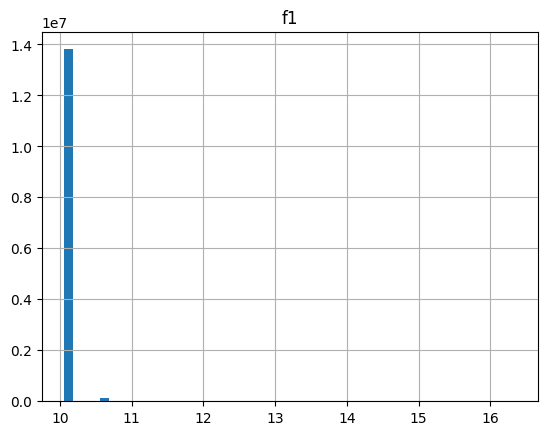

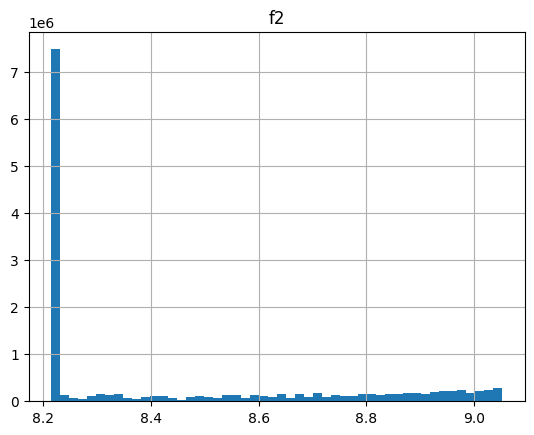

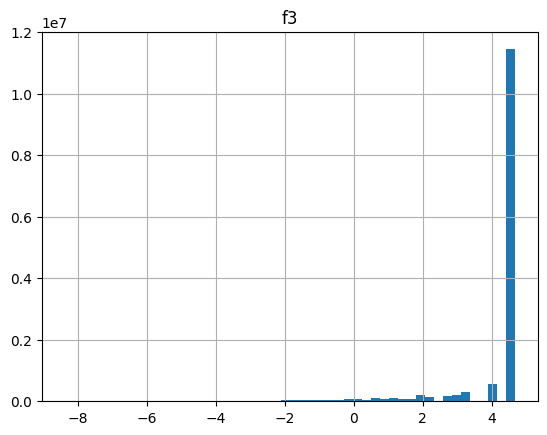

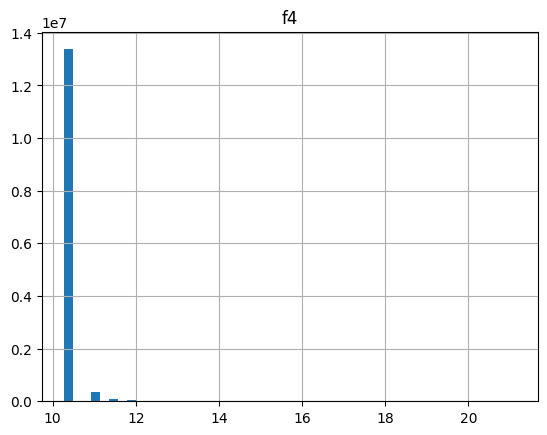

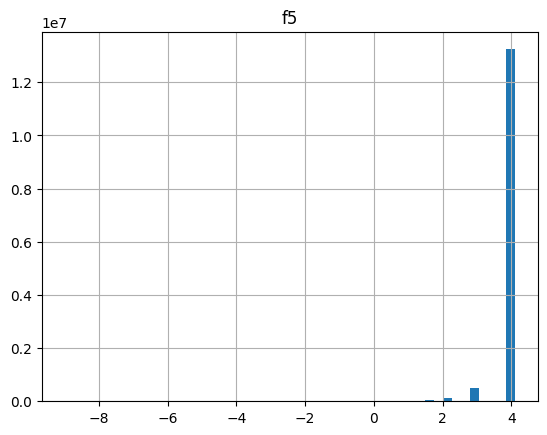

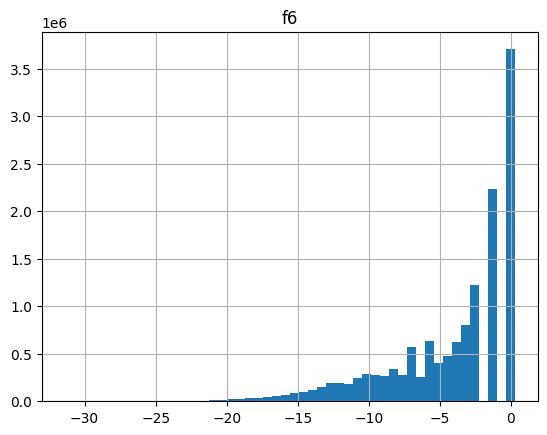

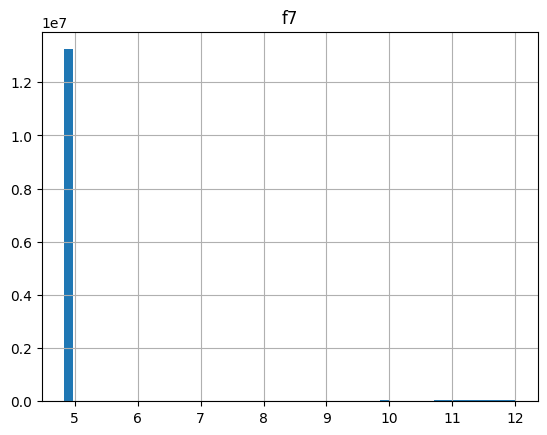

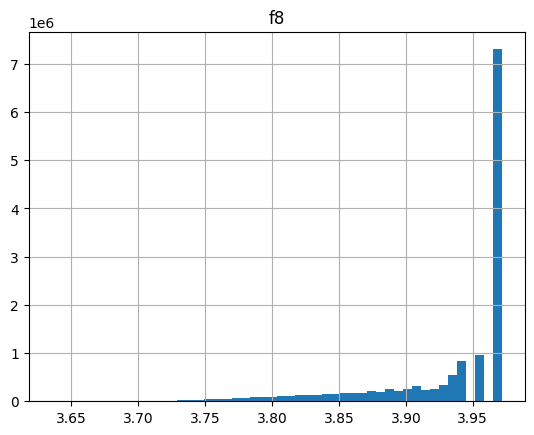

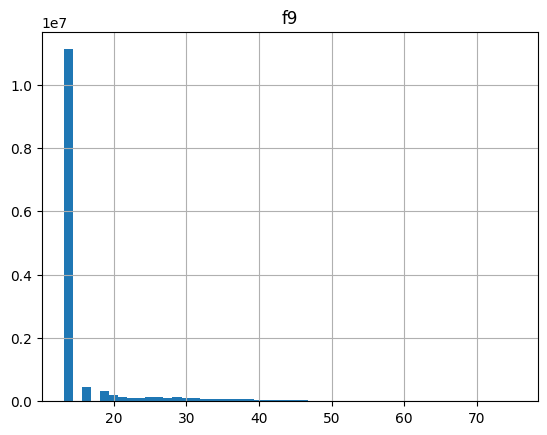

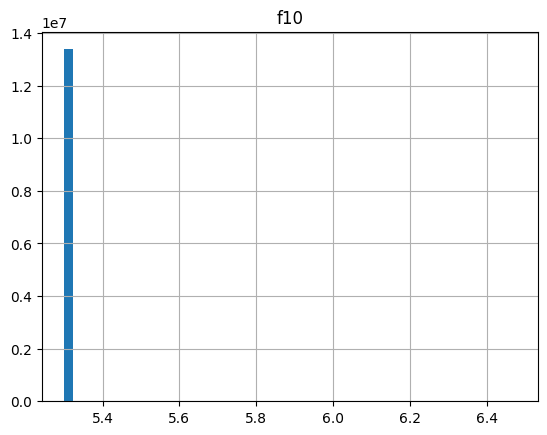

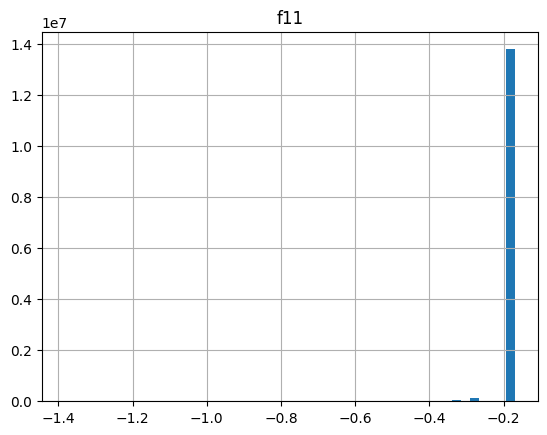

In [31]:
## checking for histogram

import matplotlib.pyplot as plt

features =['f0','f1','f2','f3','f4','f5','f6','f7','f8','f9','f10','f11']

for feature in features:
    plt.figure()
    df[feature].hist(bins=50)
    plt.title(feature)
    plt.show()




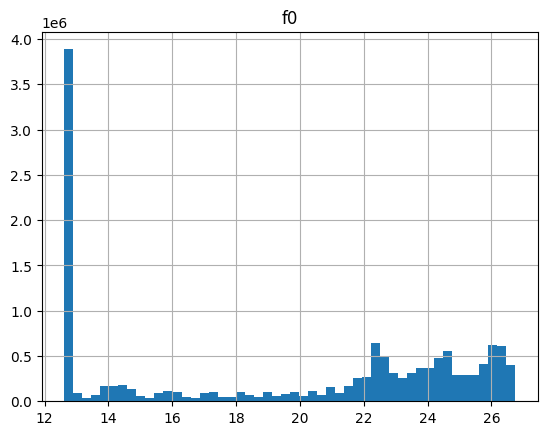

In [35]:
features =['f0']

for feature in features:
    plt.figure()
    df[feature].hist(bins=50)
    plt.title(feature)
    plt.show()

In [36]:
df['f0'].describe()

## note that min=25% which means that at least a quarter of all 13.9 million rows have exact same values.

count    1.397959e+07
mean     1.962030e+01
std      5.377464e+00
min      1.261636e+01
25%      1.261636e+01
50%      2.192341e+01
75%      2.443646e+01
max      2.674526e+01
Name: f0, dtype: float64

### KDE — a smoothed view of the same data, with one important caveat for `f0`

**What it is:** a Kernel Density Estimate places a small smooth bump (a "kernel")
at every data point, then sums them all up and normalizes — producing a
continuous curve estimate of the shape, built directly from the real sample
(unlike the artifact's bell curves, which were the idealized math formula, not
derived from data).

**Why it matters / when to use it:**
- A histogram's shape can shift noticeably just by changing `bins=` — KDE
  removes that arbitrary binning choice, so it's useful for judging a
  distribution's *overall* shape (skew, number of modes) without wondering
  "is that bump real or just a binning artifact?"
- Good for overlaying multiple distributions to compare shapes directly
  (e.g. a feature's distribution in treatment vs. control — relevant for
  Session 5's balance check).

**The important caveat, specific to `f0`:** KDE assumes the underlying density
is smooth. `f0` is the opposite of smooth — it has a single value covering
~28% of all rows, a sharp point-mass, not a smooth peak. KDE will **blur that
spike into a soft bump**, understating just how extreme and sudden the real
concentration is. For a feature like this, the histogram is actually *more*
honest than the KDE — worth comparing both side by side (as in the cell below)
to see the smoothing effect directly rather than trusting the KDE alone.

**On performance:** `.plot(kind='kde')` uses `scipy.stats.gaussian_kde`, which
sums contributions from every row for each point on its plotting grid — with
13.98M rows this can be slow (seconds to a couple minutes). If needed, KDE a
random sample instead; it won't meaningfully change the shape at this scale:
`df['f0'].sample(200_000, random_state=0).plot(kind='kde')`.

In [ ]:
# Use df.plot(kind='hist') instead of df.hist()

# density=True: rescales the histogram so total bar area sums to 1 (a "density"
# scale), instead of raw counts. Needed because the KDE line below is also
# always on a density scale - without this, the histogram's millions-of-rows
# counts would dwarf the KDE curve, making the overlay meaningless.
# alpha=0.5: 50% transparency on the bars, so the KDE line is visible through them.
# The return value of .plot() is the matplotlib Axes it drew on - captured into `ax`.

ax = df['f0'].plot(kind='hist', density=True, alpha=0.5)

# ax=ax: explicitly tells this second plot call to draw onto the SAME axes
# captured above, instead of guessing via plt.gca() - this is the "pass the
# axis explicitly" habit from the matplotlib loop discussion, applied correctly.
# color='red': makes the KDE line visually distinct from the (default blue) bars.
df['f0'].plot(kind='kde', ax=ax, color='red')

plt.show()
